In [4]:
# Step 0: Sirf libraries missing hon to neeche wali line uncomment karke run karein.
# %pip install pandas numpy matplotlib seaborn scikit-learn joblib ipykernel

In [5]:
# Step 1: Data, charts aur machine learning ki libraries import karein.
from pathlib import Path
import re
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (make_scorer, precision_score, recall_score, f1_score,
    accuracy_score, roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__)

Python: 3.14.7 | scikit-learn: 1.9.1


## 2. Dataset load aur quality checks


In [6]:
# CSV same folder mein rakhein; input file ko modify nahi karte.
DATA_PATH = Path('credit.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError('credit.csv ko notebook ke same folder mein rakhein.')
raw = pd.read_csv(DATA_PATH)
assert 'default' in raw.columns, 'Target column default missing hai.'
assert raw['default'].notna().all(), 'Missing target labels ko investigate karein.'
assert set(raw['default'].unique()) == {0, 1}, 'Target 0/1 hona chahiye.'
print('Rows, columns:', raw.shape)
display(raw.head())
raw.info()
display(raw.isna().sum().sort_values(ascending=False).to_frame('missing_count'))
print('Duplicates excluding ID:', raw.drop(columns='observation_id').duplicated().sum())
display(raw['default'].value_counts().sort_index().to_frame('applicants'))
# Gender ke against missing status check karein: systematic missingness ho sakti hai.
display(pd.crosstab(raw['gender'], raw['personal_status'].isna(), colnames=['status_missing']))

Rows, columns: (1000, 23)


,observation_id,checking_balance,months_loan_duration,credit_history,purpose,amount,savings_balance,employment_length,installment_rate,personal_status,...,age,installment_plan,housing,existing_credits,default,dependents,telephone,foreign_worker,job,gender
0,0,-43.0,6,critical,radio/tv,1169,NaN,13 years,4,single,...,67,none,own,2,0,1,2.349340e+09,yes,skilled employee,male
1,1,75.0,48,repaid,radio/tv,5951,89.0,2 years,2,NaN,...,22,none,own,1,1,1,NaN,yes,skilled employee,female
2,2,NaN,12,critical,education,2096,24.0,5 years,2,single,...,49,none,own,1,0,2,NaN,yes,unskilled resident,male
3,3,-32.0,42,repaid,furniture,7882,9.0,5 years,2,single,...,45,none,for free,1,0,2,NaN,yes,skilled employee,male
4,4,-23.0,24,delayed,car (new),4870,43.0,3 years,3,single,...,53,none,for free,2,1,2,NaN,yes,skilled employee,male


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   observation_id        1000 non-null   int64  
 1   checking_balance      606 non-null    float64
 2   months_loan_duration  1000 non-null   int64  
 3   credit_history        1000 non-null   str    
 4   purpose               1000 non-null   str    
 5   amount                1000 non-null   int64  
 6   savings_balance       817 non-null    float64
 7   employment_length     938 non-null    str    
 8   installment_rate      1000 non-null   int64  
 9   personal_status       690 non-null    str    
 10  other_debtors         1000 non-null   str    
 11  residence_history     870 non-null    str    
 12  property              1000 non-null   str    
 13  age                   1000 non-null   int64  
 14  installment_plan      1000 non-null   str    
 15  housing               1000 non-nu

,missing_count
telephone,596
checking_balance,394
personal_status,310
savings_balance,183
residence_history,130
employment_length,62
observation_id,0
amount,0
purpose,0
credit_history,0


Duplicates excluding ID: 0


,applicants
default,
0,700
1,300


status_missing,False,True
gender,,
female,0,310
male,690,0


## 3. Fixed cleaning aur untouched test split



In [7]:
# Step 3: Mixed duration text ko aik common numeric unit mein convert karein.
def duration_to_months(value):
    if pd.isna(value):
        return np.nan
    match = re.fullmatch(r'(\d+(?:\.\d+)?)\s+(years?|months?)', str(value).strip().lower())
    if match is None:
        raise ValueError(f'Unexpected duration: {value}')
    amount, unit = match.groups()
    return float(amount) * (12 if unit.startswith('year') else 1)

df = raw.copy()
df['employment_months'] = df['employment_length'].apply(duration_to_months)
df['residence_months'] = df['residence_history'].apply(duration_to_months)
df = df.drop(columns=['observation_id', 'telephone', 'employment_length', 'residence_history'])
X = df.drop(columns='default')
y = df['default']
# Test data model/threshold selection mein use nahi hoga.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
train_df = X_train.assign(default=y_train)
print('Training:', X_train.shape, '| Test:', X_test.shape)
display(pd.DataFrame({'train': y_train.value_counts(), 'test': y_test.value_counts()}))

Training: (800, 20) | Test: (200, 20)


,train,test
default,,
0,560,140
1,240,60


## 4. Training-data EDA


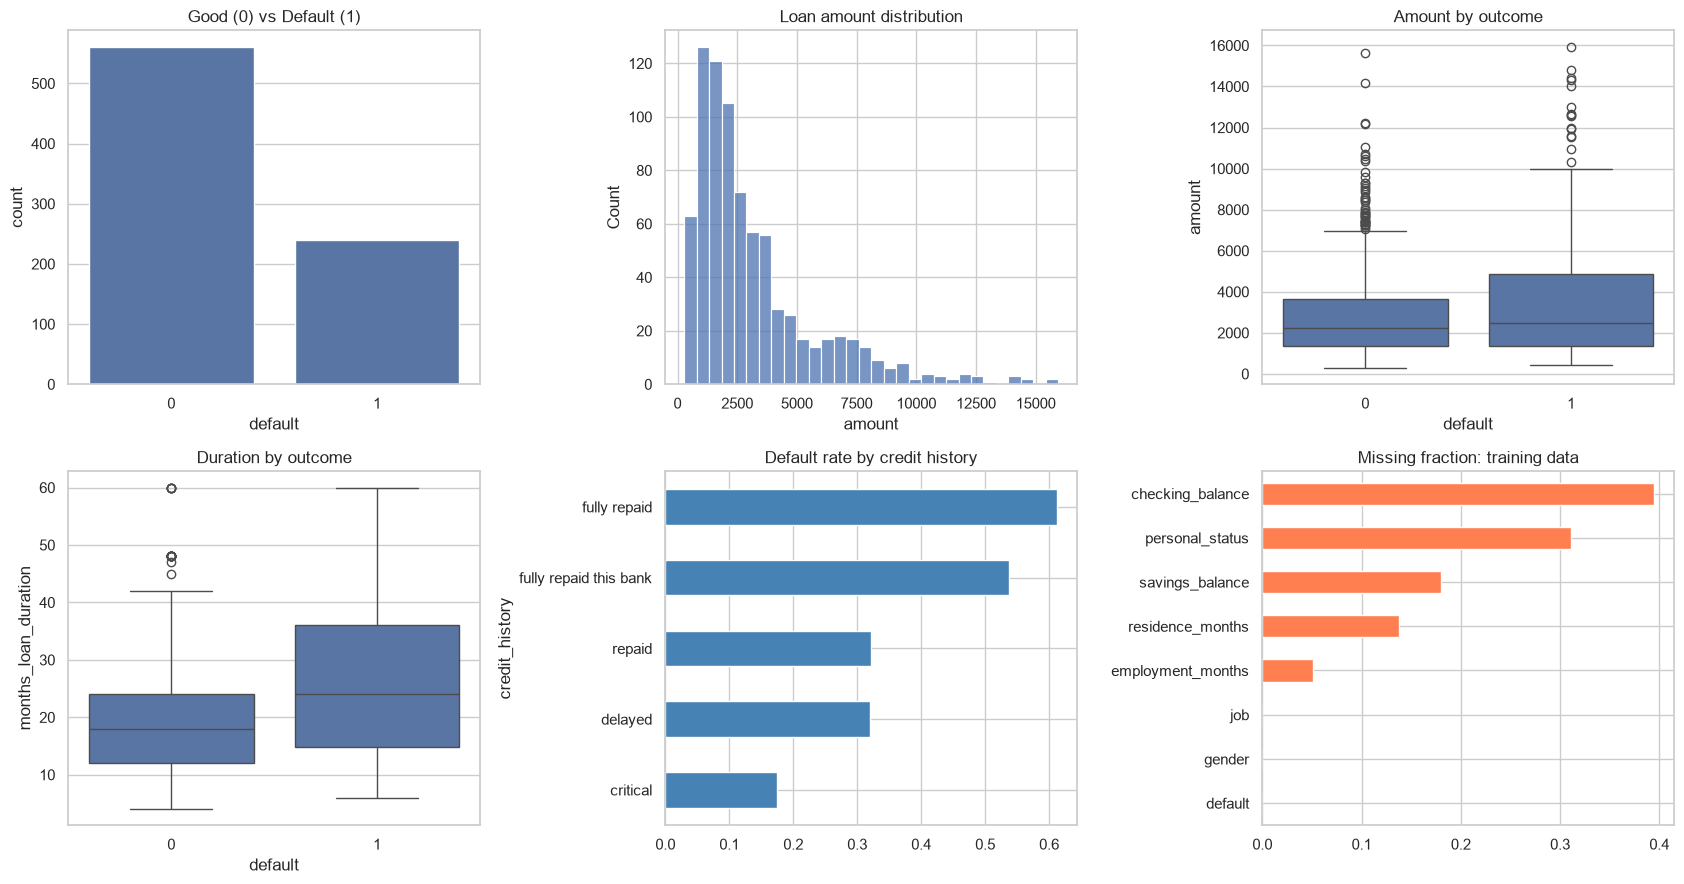

credit_history


,applicants,default_rate
credit_history,,
fully repaid,31,0.612903
fully repaid this bank,41,0.536585
repaid,416,0.322115
delayed,72,0.319444
critical,240,0.175000


purpose


,applicants,default_rate
purpose,,
education,40,0.500000
repairs,18,0.388889
car (new),194,0.360825
others,6,0.333333
business,79,0.329114
furniture,149,0.328859
domestic appliances,10,0.300000
radio/tv,215,0.213953
retraining,5,0.200000


Training default rate: 0.3


,amount,months_loan_duration
default,,
0,2242.5,18.0
1,2467.5,24.0


In [8]:
# Step 4: Class imbalance, amounts, duration aur missingness visualize karein.
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
sns.countplot(data=train_df, x='default', ax=axes[0, 0])
axes[0, 0].set_title('Good (0) vs Default (1)')
sns.histplot(data=train_df, x='amount', bins=30, ax=axes[0, 1])
axes[0, 1].set_title('Loan amount distribution')
sns.boxplot(data=train_df, x='default', y='amount', ax=axes[0, 2])
axes[0, 2].set_title('Amount by outcome')
sns.boxplot(data=train_df, x='default', y='months_loan_duration', ax=axes[1, 0])
axes[1, 0].set_title('Duration by outcome')
rates = train_df.groupby('credit_history')['default'].mean().sort_values()
rates.plot.barh(ax=axes[1, 1], color='steelblue')
axes[1, 1].set_title('Default rate by credit history')
train_df.isna().mean().sort_values().tail(8).plot.barh(ax=axes[1, 2], color='coral')
axes[1, 2].set_title('Missing fraction: training data')
plt.tight_layout()
plt.show()
for column in ['credit_history', 'purpose']:
    print(column)
    display(train_df.groupby(column)['default'].agg(applicants='size', default_rate='mean').sort_values('default_rate', ascending=False))
print('Training default rate:', round(y_train.mean(), 3))
display(train_df.groupby('default')[['amount', 'months_loan_duration']].median())

## 5. Leakage-safe preprocessing


In [9]:
# Step 5: Numeric aur text columns ke liye separate transformations banayein.
numeric_columns = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_columns = X_train.select_dtypes(exclude=np.number).columns.tolist()
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='unknown')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_columns),
    ('categorical', categorical_pipeline, categorical_columns)
])
print('Numeric features:', numeric_columns)
print('Categorical features:', categorical_columns)

Numeric features: ['checking_balance', 'months_loan_duration', 'amount', 'savings_balance', 'installment_rate', 'age', 'existing_credits', 'dependents', 'employment_months', 'residence_months']
Categorical features: ['credit_history', 'purpose', 'personal_status', 'other_debtors', 'property', 'installment_plan', 'housing', 'foreign_worker', 'job', 'gender']


## 6. Baseline aur four classifiers


,model,accuracy,accuracy_std,precision,precision_std,recall,recall_std,f1,f1_std,roc_auc,roc_auc_std,average_precision,average_precision_std
3,Random Forest,0.749,0.038,0.580,0.062,0.587,0.071,0.583,0.065,0.791,0.040,0.617,0.070
4,SVM,0.709,0.033,0.513,0.045,0.654,0.047,0.574,0.041,0.777,0.041,0.615,0.075
1,Logistic Regression,0.702,0.035,0.502,0.044,0.675,0.092,0.575,0.059,0.763,0.054,0.586,0.069
0,Baseline,0.700,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.500,0.000,0.300,0.000
2,Decision Tree,0.642,0.019,0.440,0.019,0.696,0.060,0.538,0.026,0.675,0.043,0.434,0.055


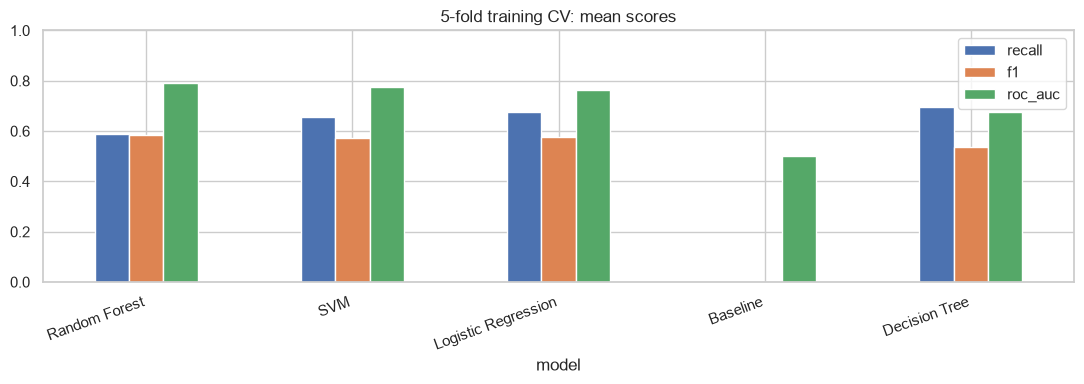

In [10]:
# Step 6: Same folds aur same metrics se fair model comparison karein.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
models = {
    'Baseline': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=3000, class_weight='balanced', random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=150, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=1),
    'SVM': SVC(class_weight='balanced', random_state=RANDOM_STATE)
}
scoring = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0),
    'roc_auc': 'roc_auc',
    'average_precision': 'average_precision'
}
rows = []
for name, model in models.items():
    pipe = Pipeline([('preprocessor', clone(preprocessor)), ('model', model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    row = {'model': name}
    for metric in scoring:
        row[metric] = scores['test_' + metric].mean()
        row[metric + '_std'] = scores['test_' + metric].std()
    rows.append(row)
comparison = pd.DataFrame(rows).sort_values(['accuracy', 'f1'], ascending=False)
display(comparison.round(3))
comparison.to_csv(OUT / 'cv_model_comparison.csv', index=False)
comparison.set_index('model')[['recall', 'f1', 'roc_auc']].plot.bar(figsize=(11, 4), ylim=(0, 1))
plt.title('5-fold training CV: mean scores')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

## 7. Hyperparameter tuning aur model selection


In [11]:
# Step 7: Test set use kiye baghair accuracy ke liye parameters select karein.
grids = {
    'Logistic Regression': {'model__C': [0.1, 1, 10], 'model__class_weight': [None, 'balanced']},
    'Decision Tree': {'model__max_depth': [3, 5, 8], 'model__min_samples_leaf': [5, 15], 'model__class_weight': [None, 'balanced']},
    'Random Forest': {'model__max_depth': [None, 6], 'model__min_samples_leaf': [2, 6], 'model__class_weight': [None, 'balanced']},
    'SVM': {'model__C': [0.1, 1, 10], 'model__class_weight': [None, 'balanced']}
}
searches = {}
tuned_rows = []
for name, grid in grids.items():
    pipe = Pipeline([('preprocessor', clone(preprocessor)), ('model', clone(models[name]))])
    search = GridSearchCV(pipe, grid, scoring=scoring, refit='accuracy', cv=cv, n_jobs=1)
    search.fit(X_train, y_train)
    searches[name] = search
    tuned_rows.append({'model': name, 'cv_accuracy': search.best_score_, 'cv_f1': search.cv_results_['mean_test_f1'][search.best_index_], 'parameters': str(search.best_params_)})
tuned_results = pd.DataFrame(tuned_rows).sort_values(['cv_accuracy', 'cv_f1'], ascending=False)
display(tuned_results)
winner_name = tuned_results.iloc[0]['model']
best_model = searches[winner_name].best_estimator_
print('Selected model:', winner_name)

,model,cv_accuracy,cv_f1,parameters
3,SVM,0.76625,0.500672,"{'model__C': 1, 'model__class_weight': None}"
0,Logistic Regression,0.75250,0.501853,"{'model__C': 0.1, 'model__class_weight': None}"
2,Random Forest,0.75125,0.455107,"{'model__class_weight': None, 'model__max_dept..."
1,Decision Tree,0.72000,0.386212,"{'model__class_weight': None, 'model__max_dept..."


Selected model: SVM


## 8. Training-only threshold analysis


Score type: decision_function
Minimum training OOF Default recall: 66.7%
Default cutoff: 0.0 | Recall-constrained cutoff: -0.5910178182053846


,training OOF result
threshold,-0.591018
accuracy,0.710000
precision,0.512739
recall,0.670833
f1,0.581227


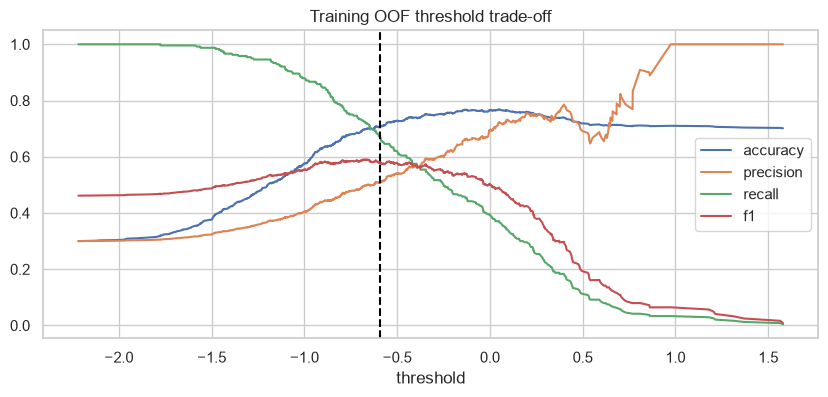

In [12]:
# Step 8: Training OOF recall >= 2/3 rakhte hue accuracy maximize karein.
uses_probability = hasattr(best_model, 'predict_proba')
method = 'predict_proba' if uses_probability else 'decision_function'
oof = cross_val_predict(clone(best_model), X_train, y_train, cv=cv, method=method, n_jobs=1)
oof_scores = oof[:, 1] if uses_probability else oof
default_threshold = 0.5 if uses_probability else 0.0
thresholds = np.unique(np.r_[oof_scores, default_threshold])
threshold_rows = []
for threshold in thresholds:
    pred = (oof_scores >= threshold).astype(int)
    threshold_rows.append({'threshold': threshold, 'accuracy': accuracy_score(y_train, pred),
        'precision': precision_score(y_train, pred, zero_division=0), 'recall': recall_score(y_train, pred),
        'f1': f1_score(y_train, pred)})
threshold_table = pd.DataFrame(threshold_rows)
min_default_recall = 2 / 3
eligible_thresholds = threshold_table[threshold_table['recall'] >= min_default_recall]
if eligible_thresholds.empty:
    raise ValueError('No threshold reached the required training OOF Default recall.')
selected = eligible_thresholds.sort_values(['accuracy', 'recall', 'f1'], ascending=False).iloc[0]
selected_threshold = float(selected['threshold'])
print('Score type:', method)
print(f'Minimum training OOF Default recall: {min_default_recall:.1%}')
print('Default cutoff:', default_threshold, '| Recall-constrained cutoff:', selected_threshold)
display(selected.to_frame('training OOF result'))
threshold_table.sort_values('threshold').plot(x='threshold', y=['accuracy', 'precision', 'recall', 'f1'], figsize=(10, 4))
plt.axvline(selected_threshold, color='black', linestyle='--')
plt.title('Training OOF threshold trade-off')
plt.show()

## 9. Final held-out test evaluation


Final model: SVM
              precision    recall  f1-score   support

        Good       0.89      0.74      0.80       140
     Default       0.56      0.78      0.65        60

    accuracy                           0.75       200
   macro avg       0.72      0.76      0.73       200
weighted avg       0.79      0.75      0.76       200



,test_result
accuracy,0.750
default_precision,0.560
default_recall,0.783
default_f1,0.653
roc_auc,0.843
average_precision,0.745


Defaults detected: 47; missed: 13; Good applicants flagged: 37; Good correctly identified: 103


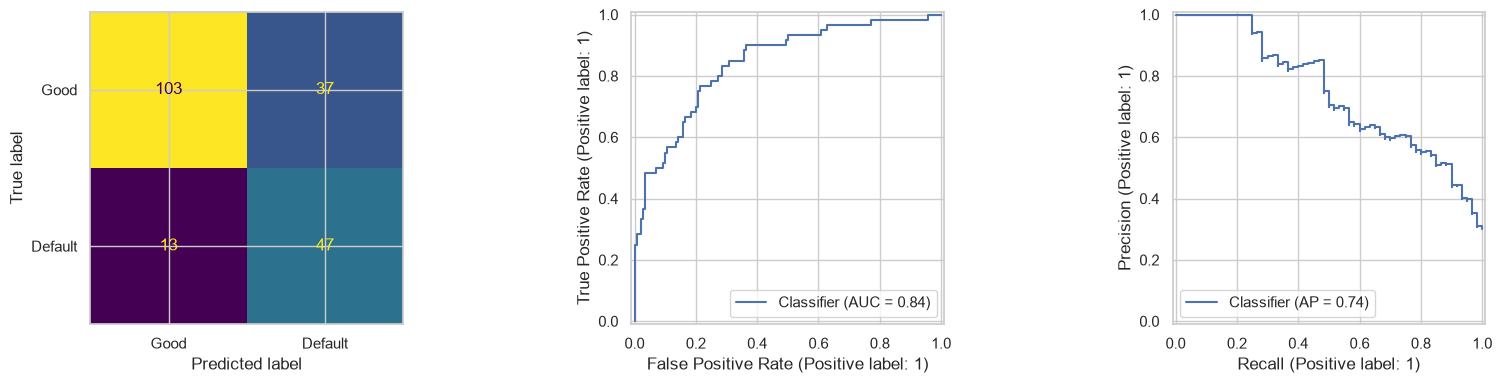

In [13]:
# Step 9: Final model ko full training set par fit karke test evaluate karein.
best_model.fit(X_train, y_train)
test_raw_scores = getattr(best_model, method)(X_test)
test_scores = test_raw_scores[:, 1] if uses_probability else test_raw_scores
pred_test = (test_scores >= selected_threshold).astype(int)
print('Final model:', winner_name)
print(classification_report(y_test, pred_test, target_names=['Good', 'Default'], zero_division=0))
metrics = {
    'accuracy': accuracy_score(y_test, pred_test),
    'default_precision': precision_score(y_test, pred_test, zero_division=0),
    'default_recall': recall_score(y_test, pred_test),
    'default_f1': f1_score(y_test, pred_test),
    'roc_auc': roc_auc_score(y_test, test_scores),
    'average_precision': average_precision_score(y_test, test_scores)
}
display(pd.Series(metrics, name='test_result').to_frame().round(3))
tn, fp, fn, tp = confusion_matrix(y_test, pred_test, labels=[0, 1]).ravel()
print(f'Defaults detected: {tp}; missed: {fn}; Good applicants flagged: {fp}; Good correctly identified: {tn}')
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=['Good', 'Default'], ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, test_scores, ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_test, test_scores, ax=axes[2])
plt.tight_layout()
plt.show()

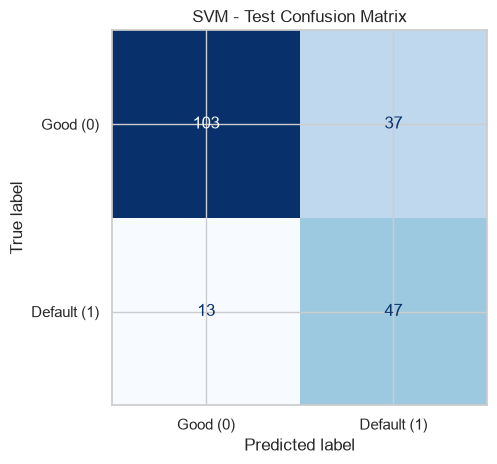

In [14]:
# Standalone confusion matrix chart for the held-out test set.
cm = confusion_matrix(y_test, pred_test, labels=[0, 1])
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Good (0)', 'Default (1)']
)
cm_display.plot(cmap='Blues', values_format='d', colorbar=False)
plt.title(f'{winner_name} - Test Confusion Matrix')
plt.tight_layout()
plt.show()

## 10. Model explanation aur subgroup diagnostic


,feature,mean_auc_drop,std
0,checking_balance,0.090490,0.008007
18,employment_months,0.040217,0.003568
1,months_loan_duration,0.035625,0.003734
5,savings_balance,0.032940,0.003555
19,residence_months,0.032649,0.004993
6,installment_rate,0.024507,0.001715
3,purpose,0.021366,0.001784
4,amount,0.017914,0.002501
11,installment_plan,0.016098,0.003175
2,credit_history,0.015101,0.000876


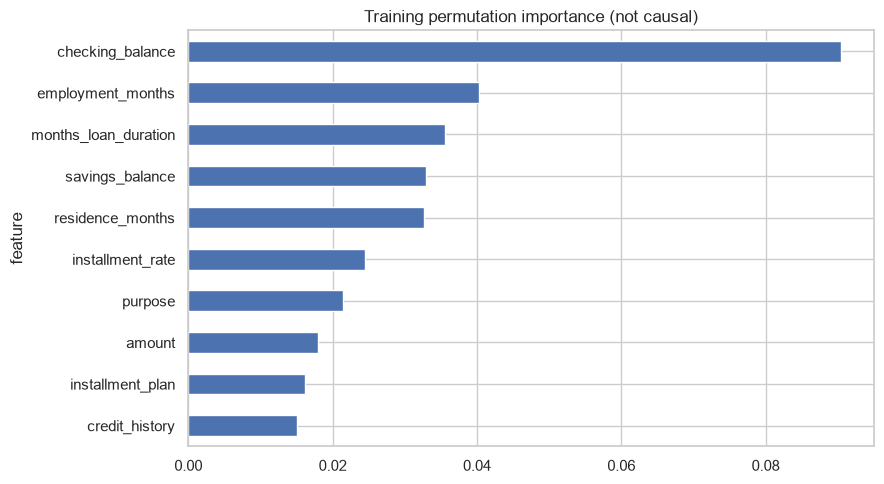

,gender,n,actual_defaults,recall,false_positive_rate
0,female,61,20,0.85,0.365854
1,male,139,40,0.75,0.222222


In [15]:
# Step 10: Original input columns ki importance compare karein.
importance = permutation_importance(best_model, X_train, y_train, scoring='roc_auc', n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
feature_importance = pd.DataFrame({'feature': X_train.columns, 'mean_auc_drop': importance.importances_mean,
    'std': importance.importances_std}).sort_values('mean_auc_drop', ascending=False)
display(feature_importance.head(10))
feature_importance.head(10).sort_values('mean_auc_drop').plot.barh(x='feature', y='mean_auc_drop', legend=False, figsize=(9, 5))
plt.title('Training permutation importance (not causal)')
plt.tight_layout()
plt.show()
audit = X_test[['gender']].copy()
audit['actual'] = y_test
audit['predicted'] = pred_test
audit_rows = []
for group, part in audit.groupby('gender'):
    gtn, gfp, gfn, gtp = confusion_matrix(part['actual'], part['predicted'], labels=[0, 1]).ravel()
    audit_rows.append({'gender': group, 'n': len(part), 'actual_defaults': int(gtp + gfn),
        'recall': gtp / (gtp + gfn) if gtp + gfn else np.nan,
        'false_positive_rate': gfp / (gfp + gtn) if gfp + gtn else np.nan})
display(pd.DataFrame(audit_rows))

## 11. Business conclusion


In [16]:
# Step 11: Actual calculated numbers se conclusion banayein; invented accuracy use nahi karte.
print(f'Selected classifier: {winner_name}')
print(f'Test recall: {metrics["default_recall"]:.1%}; F1: {metrics["default_f1"]:.3f}; ROC-AUC: {metrics["roc_auc"]:.3f}')
print(f'Of {tp + fn} actual defaulters, {tp} were detected and {fn} were missed.')
print(f'{fp} of {tn + fp} Good applicants were flagged for review.')
print('Most influential training features:', ', '.join(feature_importance.head(5)['feature']))
print('Limitations: 1,000 records; substantial missingness; gender-linked missing status; no verified deployment savings.')

Selected classifier: SVM
Test recall: 78.3%; F1: 0.653; ROC-AUC: 0.843
Of 60 actual defaulters, 47 were detected and 13 were missed.
37 of 140 Good applicants were flagged for review.
Most influential training features: checking_balance, employment_months, months_loan_duration, savings_balance, residence_months
Limitations: 1,000 records; substantial missingness; gender-linked missing status; no verified deployment savings.


## 12. Save pipeline, results aur sample inference


In [17]:
# Step 12: Fitted preprocessing + model + selected threshold ko saath save karein.
bundle = {'pipeline': best_model, 'threshold': selected_threshold, 'score_method': method,
    'feature_columns': X_train.columns.tolist(), 'model_name': winner_name,
    'sklearn_version': sklearn.__version__}
joblib.dump(bundle, OUT / 'credit_risk_bundle.joblib')
pd.Series(metrics).to_csv(OUT / 'final_test_metrics.csv', header=['value'])
feature_importance.to_csv(OUT / 'training_feature_importance.csv', index=False)
threshold_table.to_csv(OUT / 'training_threshold_analysis.csv', index=False)
# Test set ka aik sample sirf inference workflow demonstrate karne ke liye.
loaded = joblib.load(OUT / 'credit_risk_bundle.joblib')
sample = X_test.iloc[[0]].copy()
raw_score = getattr(loaded['pipeline'], loaded['score_method'])(sample)
score = float(raw_score[0, 1] if uses_probability else raw_score[0])
print('Sample default probability:' if uses_probability else 'Sample decision score:', round(score, 4))
print('Predicted class:', int(score >= loaded['threshold']))
print('Saved files:', [p.name for p in OUT.iterdir() if p.is_file()])

Sample decision score: -1.0803
Predicted class: 0
Saved files: ['credit_risk_bundle.joblib', 'cv_model_comparison.csv', 'final_test_metrics.csv', 'training_feature_importance.csv', 'training_threshold_analysis.csv']
